# 한국어 대화 요약: 7시간 미만 전체 실습 v3

**2026-09-20 작성 · V3 전체 실행 및 독립 내부 Test 완료 · 목표: 7시간 미만의 재현 가능한 실험**

이 파일에 데이터 점검 → 분할 → 전처리 → 기준 모델 → KoBART 학습 → 생성 설정 선택 → Validation 전체 평가 → 독립 내부 Test →
오류 분석 → 모델 저장·재로딩 → 새 대화 요약을 모두 담았다.
기존 프로젝트의 Python 파일이나 이전 분석 결과 없이 이 노트북과 원본 JSON 18개만 사용한다.

### 실행 전에

1. 원본 데이터가 있는 **팀프로젝트4 폴더**에서 이 파일을 연다.
2. **Python 3.10~3.12, 권장 3.11의 새 커널**에서 위에서 아래로 실행한다.
3. 코드 01은 실행 환경에 패키지를 설치한다. 처음 설치·모델 다운로드에는 인터넷이 필요하다.
4. 확인된 PC는 **RTX 5060 Laptop GPU 8GB**다. v1 실측에서 1,500회 업데이트가 약 15.2분 걸렸으므로,
   GPU 모드는 Train 후보 대부분인 265,000건·최대 33,126회 업데이트(약 2epoch)로 확장했다.
   GPU를 사용할 수 없으면 CPU 흐름 확인용 128건·20회 업데이트로 내려간다.
5. 전체 소프트 예산은 첫 셀부터 **6시간 45분**, 학습은 최대 **5시간 45분**이고
   학습 종료 후 최소 **45분**을 남기도록 한다. 최종 생성 평가에도 30분 제한을 둔다.
6. 시간 검사는 연산 사이에 이루어진다. 다운로드 지연, 단일 연산, 저장, 사용자의 셀 간 대기까지
   강제 종료하는 보장은 아니다. 자동 전체 실행 시 7시간 이내 완주를 지향하는 설정이다.

**분할:** 공식 Train 안에서 학습/개발 후보를 나눈 뒤 표본을 추출한다.
개발 데이터에서 생성 방법까지 고정한 뒤 공식 Validation 전체를 한 번 평가한다. 그 다음 공식 Train에서 학습·Dev에 한 번도 사용하지 않은 잔여 4,992건을 독립 내부 Test로 복원해 마지막으로 평가한다.
공식 Test 파일은 없으므로 Validation 점수는 **공식 Validation 전체 평가**, Test 점수는 **공식 Train 미사용 holdout에 대한 내부 Test**로 구분한다.

**결과 위치:** output/notebook_runs/실행시각/ — 실행마다 새 폴더를 만든다.
학습 표본 26.5만 건은 해시로 개발 후보를 제외한 Train의 대부분이다. 시간 제한 때문에 2epoch를 채우지 못할 수 있으며 최적 성능을 보장하지 않는다.

## 코드 01. 실행 시계와 환경 설치

RTX 50 계열을 위해 CUDA 12.8 PyTorch 빌드를 사용한다. 시스템 CUDA Toolkit을 따로 설치하는 과정은 아니다.
이미 핵심 패키지를 import한 커널에서 버전 교체가 필요하면 커널 재시작을 안내한다.
INSTALL_PACKAGES=False는 아래 버전이 준비된 환경에서만 사용한다.
현재 환경 전체를 덮어쓰지 않으려면 Python 3.11 전용 가상환경을 권장한다.

In [1]:
import sys, os, time, subprocess, importlib.metadata as metadata
from datetime import datetime

RUN_STARTED = time.monotonic()  # 설치 시간도 포함. 이 셀 재실행 시 시계가 초기화된다.
INSTALL_PACKAGES = True
TOTAL_BUDGET_HOURS = 6.75
GLOBAL_DEADLINE = RUN_STARTED + TOTAL_BUDGET_HOURS * 3600
assert (3, 10) <= sys.version_info[:2] <= (3, 12), 'Python 3.10~3.12 커널을 선택하세요. 권장: 3.11'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['HF_HUB_DOWNLOAD_TIMEOUT'] = '120'

def installed_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

pins = {
    'numpy':'1.26.4', 'pandas':'2.2.3', 'matplotlib':'3.9.4',
    'transformers':'4.44.2', 'tokenizers':'0.19.1',
    'huggingface-hub':'0.34.4', 'safetensors':'0.6.2',
    'ijson':'3.3.0', 'rouge-score':'0.1.2', 'tqdm':'4.67.1',
}
module_names = {'huggingface-hub':'huggingface_hub', 'rouge-score':'rouge_score'}
if INSTALL_PACKAGES:
    loaded = [name for name in pins if module_names.get(name,name) in sys.modules
              and installed_version(name) != pins[name]]
    if loaded:
        raise RuntimeError(f'커널을 재시작하고 코드 01부터 실행하세요. 이미 로드된 교체 대상: {loaded}')
    needed = [f'{name}=={version}' for name,version in pins.items()
              if installed_version(name) != version]
    if needed:
        subprocess.run([sys.executable,'-m','pip','install','--disable-pip-version-check',*needed],
                       check=True,timeout=1800)
    if installed_version('torch') != '2.8.0+cu128':
        if 'torch' in sys.modules:
            raise RuntimeError('torch가 이미 로드되었습니다. 커널 재시작 후 코드 01부터 실행하세요.')
        subprocess.run([sys.executable,'-m','pip','install','torch==2.8.0',
                        '--index-url','https://download.pytorch.org/whl/cu128'],
                       check=True,timeout=1800)

print('Python:',sys.version.split()[0],'| torch:',installed_version('torch'))
print('환경 준비 경과(분):',round((time.monotonic()-RUN_STARTED)/60,1))

Python: 3.10.11 | torch: 2.8.0+cu128
환경 준비 경과(분): 0.0


## 코드 02. 설정과 GPU 검사

train_n은 학습 대화 수, micro_batch는 한 번 메모리에 올리는 수,
effective_batch는 가중치를 한 번 갱신할 때 사용하는 대화 수다.
기본값은 2개씩 8회 gradient를 누적해 유효 배치 16을 만든다.
GPU 감지 후 실제 작은 행렬 연산도 검사한다. 실패하면 CPU 흐름 확인 모드로 전환한다.
DATA_ROOT_OVERRIDE가 비어 있으면 현재 폴더와 상위 폴더를 탐색한다.

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from contextlib import nullcontext
import gc, hashlib, json, math, random, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import ijson
import torch
from tqdm.auto import tqdm
from IPython.display import display, Markdown
from transformers import (PreTrainedTokenizerFast, BartForConditionalGeneration,
                          GenerationConfig, get_linear_schedule_with_warmup)
from huggingface_hub import HfApi
from rouge_score import rouge_scorer

DATA_ROOT_OVERRIDE = ''  # 예: r'C:\Users\use\Documents\KDT17\팀프로젝트4'
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
cuda_ok = torch.cuda.is_available()
if cuda_ok:
    try:
        probe = torch.ones((32,32),device='cuda')
        probe_result = probe @ probe
        torch.cuda.synchronize()
        del probe, probe_result
        torch.cuda.manual_seed_all(SEED)
    except RuntimeError as exc:
        print('GPU 실행 검사 실패:',str(exc)[:300])
        cuda_ok = False

DEVICE = torch.device('cuda' if cuda_ok else 'cpu')
PROFILE = 'gpu_7h' if cuda_ok else 'cpu_smoke'
CFG = dict(
    model_id='gogamza/kobart-base-v2',revision='main',seed=SEED,
    train_n=265000,dev_n=10000,final_n=40000,dev_candidate_ratio=0.05,
    max_input_tokens=320,max_target_tokens=80,input_head_ratio=0.75,
    micro_batch=2,effective_batch=16,
    max_steps=33126,max_epochs=2,learning_rate=3e-5,weight_decay=0.01,warmup_ratio=0.06,
    eval_every=2500,dev_loss_n=2048,dev_loss_batch=8,patience=4,train_hours=5.75,
    post_train_reserve_minutes=45,final_generation_minutes=30,
    generation_batch=4,max_new_tokens=80,num_beams=1,
)
if not cuda_ok:
    CFG.update(train_n=128,dev_n=32,final_n=20,micro_batch=1,effective_batch=1,
               max_steps=20,max_epochs=1,eval_every=10,dev_loss_n=8,train_hours=0.25,
               generation_batch=1,max_input_tokens=192,max_new_tokens=48,final_generation_minutes=15,
               dev_loss_batch=1)
    torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
    print('CPU 흐름 확인 모드입니다. 성능 실험을 하려면 GPU 드라이버와 커널을 확인하세요.')
else:
    print('GPU:',torch.cuda.get_device_name(0))
    print('VRAM(GiB):',round(torch.cuda.get_device_properties(0).total_memory/2**30,2))
USE_BF16 = cuda_ok and torch.cuda.is_bf16_supported()
USE_FP16 = cuda_ok and not USE_BF16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
def amp_context():
    return torch.autocast(device_type='cuda',dtype=AMP_DTYPE) if cuda_ok else nullcontext()

candidates = [Path(DATA_ROOT_OVERRIDE).expanduser()] if DATA_ROOT_OVERRIDE else [Path.cwd(),*Path.cwd().parents]
DATA_ROOT = next((p.resolve() for p in candidates
                  if (p/'[라벨]한국어대화요약_train').is_dir()
                  and (p/'[라벨]한국어대화요약_valid').is_dir()),None)
if DATA_ROOT is None:
    raise FileNotFoundError('DATA_ROOT_OVERRIDE에 압축 해제된 train/valid 폴더의 부모 경로를 넣으세요.')
RUN_DIR = DATA_ROOT/'output'/'notebook_runs'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR.mkdir(parents=True,exist_ok=False)
def write_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
environment = {name:installed_version(name) for name in ['torch',*pins]}
write_json(RUN_DIR/'config.json',{'profile':PROFILE,**CFG,'packages':environment})
fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Malgun Gothic','NanumGothic','AppleGothic']:
    if font in fonts:
        plt.rcParams['font.family'] = font
        break
plt.rcParams['axes.unicode_minus'] = False
print('프로필:',PROFILE,'| 입력:',DATA_ROOT,'| 결과:',RUN_DIR)
display(pd.DataFrame(CFG.items(),columns=['설정','값']))

GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GiB): 7.93
프로필: gpu_7h | 입력: C:\Users\use\Documents\KDT17\팀프로젝트4 | 결과: C:\Users\use\Documents\KDT17\팀프로젝트4\output\notebook_runs\20260920_160110_435084


,설정,값
0,model_id,gogamza/kobart-base-v2
1,revision,main
2,seed,42
3,train_n,265000
4,dev_n,10000
5,final_n,40000
6,dev_candidate_ratio,0.05
7,max_input_tokens,320
8,max_target_tokens,80
9,input_head_ratio,0.75


## 코드 03. JSON 파일 목록과 샘플

각 주제별 파일의 data 배열에 여러 대화가 들어 있다.
약 1GB JSON 전체를 메모리에 동시에 올리지 않고 ijson으로 한 건씩 읽는다.
header.dialogueInfo는 메타 정보, body.dialogue는 입력 원문, body.summary는 정답이다.
P01 같은 화자 ID는 각 대화 내부에서만 의미가 있다.

In [3]:
FILES = {split:sorted((DATA_ROOT/f'[라벨]한국어대화요약_{split}').rglob('*.json'))
         for split in ['train','valid']}
assert all(FILES.values()), 'train 또는 valid JSON이 없습니다.'
def stream_records(path):
    with open(path,'rb') as handle:
        if handle.read(3) != b'\xef\xbb\xbf':
            handle.seek(0)
        yield from ijson.items(handle,'data.item')

file_inventory = pd.DataFrame([
    {'split':split,'file':p.name,'MB':round(p.stat().st_size/1e6,2),
     'path':str(p.relative_to(DATA_ROOT)),'mtime_ns':p.stat().st_mtime_ns}
    for split,paths in FILES.items() for p in paths
])
display(file_inventory)
file_inventory.to_csv(RUN_DIR/'source_files.csv',index=False,encoding='utf-8-sig')
reader = stream_records(FILES['train'][0])
example = next(reader)
reader.close()
display(example['header']['dialogueInfo'])
display(pd.DataFrame(example['body']['dialogue']))
print('정답 요약:',example['body']['summary'])

,split,file,MB,path,mtime_ns
0,train,개인및관계.json,249.99,[라벨]한국어대화요약_train\개인및관계.json,1651651280000000000
1,train,미용과건강.json,61.36,[라벨]한국어대화요약_train\미용과건강.json,1651651280000000000
2,train,상거래(쇼핑).json,94.68,[라벨]한국어대화요약_train\상거래(쇼핑).json,1651651280000000000
3,train,시사교육.json,47.88,[라벨]한국어대화요약_train\시사교육.json,1651651280000000000
4,train,식음료.json,105.06,[라벨]한국어대화요약_train\식음료.json,1651651280000000000
5,train,여가생활.json,126.19,[라벨]한국어대화요약_train\여가생활.json,1651651280000000000
6,train,일과직업.json,74.71,[라벨]한국어대화요약_train\일과직업.json,1651651280000000000
7,train,주거와생활.json,158.85,[라벨]한국어대화요약_train\주거와생활.json,1651651280000000000
8,train,행사.json,75.24,[라벨]한국어대화요약_train\행사.json,1651651280000000000
9,valid,개인및관계.json,31.30,[라벨]한국어대화요약_valid\개인및관계.json,1651651296000000000


{'dialogueID': '451a86a0-a699-5c49-9370-e1d79ea63506',
 'numberOfParticipants': 2,
 'numberOfUtterances': 20,
 'numberOfTurns': 8,
 'type': '일상 대화',
 'topic': '개인 및 관계'}

,utteranceID,turnID,participantID,date,time,utterance
0,U1,T1,P01,2020-06-01,08:08:00,우리 기간 언제까지나고 물어볼 수 없어
1,U2,T1,P01,2020-06-01,08:08:00,재등록 할 줄 알면 어케?
2,U3,T2,P02,2020-06-01,08:18:00,헉...
3,U4,T2,P02,2020-06-01,08:18:00,어떻게말해야되지?
4,U5,T3,P01,2020-06-01,08:43:00,그냥 자연스레..
5,U6,T3,P01,2020-06-01,08:43:00,안나오면되비
6,U7,T3,P01,2020-06-01,08:43:00,ㄱ 아저씨가 먼저 말하려나?
7,U8,T3,P01,2020-06-01,08:43:00,연장할거냐고..하면
8,U9,T3,P01,2020-06-01,08:43:00,뭐랗9?
9,U10,T4,P02,2020-06-01,08:57:00,고민해볼게요..?


정답 요약: 아저씨가 재등록에 관하여 물어보면 다음 달은 바빠서 어려울 것 같고 다음에 다시 오겠다고 대답하라고 알려준다.


## 코드 04. 전처리·층화 표본 함수

원본 순서와 화자를 유지하고 빈 발화만 제외한다. U1, U10, U2 같은 문자열 정렬을 하지 않는다.
비식별화·이모티콘 표식과 구어체는 보존한다. 정답·주제·유형은 모델 입력에 붙이지 않는다.
원문 해시로 약 5%를 개발 후보에 배정하고 주제×유형 비율에 따라 표본을 추출한다.
정확한 비율을 우선하므로 극소수 그룹은 표본에서 빠질 수 있다. 실제 분포는 코드 06에서 확인한다.
중복 검사는 정규화 후 정확히 같은 원문만 잡는다. 부분 중복과 유사 대화는 별도 과제다.

In [4]:
def clean_space(text):
    return re.sub(r'\s+',' ',str(text)).strip()

def normalize_record(row,file_name):
    info = row['header']['dialogueInfo']
    turns = row['body']['dialogue']
    summary = clean_space(row['body']['summary'])
    nonempty = [(str(u['participantID']),clean_space(u['utterance'])) for u in turns
                if clean_space(u['utterance'])]
    raw_text = '\n'.join(t for _,t in nonempty)
    fingerprint = hashlib.sha256(raw_text.encode('utf-8')).hexdigest()
    return {
        'dialogue_id':str(info['dialogueID']),'topic':str(info['topic']),'type':str(info['type']),
        'source_file':file_name,'input':'\n'.join(f'{speaker}: {text}' for speaker,text in nonempty),
        'target':summary,'utterances':[text for _,text in nonempty],'fingerprint':fingerprint,
        'input_chars':len(raw_text),'summary_chars':len(summary),'utterance_count':len(nonempty),
        'participant_count':len({p for p,_ in nonempty}),'removed_empty':len(turns)-len(nonempty),
        'turn_mismatch':int(info['numberOfTurns']) != len({u['turnID'] for u in turns}),
    }

class StratifiedReservoir:
    def __init__(self,target_n,seed):
        self.target_n = target_n
        self.rng = random.Random(seed)
        self.counts = Counter()
        self.buckets = defaultdict(list)
    def add(self,record):
        key = (record['topic'],record['type'])
        self.counts[key] += 1
        bucket = self.buckets[key]
        if len(bucket) < self.target_n:
            bucket.append(record)
        else:
            j = self.rng.randrange(self.counts[key])
            if j < self.target_n:
                bucket[j] = record
    def finish(self):
        total = sum(self.counts.values())
        if not total:
            return []
        n = min(self.target_n,total)
        keys = sorted(self.counts)
        ideal = {k:n*self.counts[k]/total for k in keys}
        quotas = {k:int(math.floor(ideal[k])) for k in keys}
        order = sorted(keys,key=lambda k:(-(ideal[k]-quotas[k]),k))
        for key in order[:n-sum(quotas.values())]:
            quotas[key] += 1
        selected = []
        for key in keys:
            selected.extend(self.rng.sample(self.buckets[key],quotas[key]))
        self.rng.shuffle(selected)
        return selected

## 코드 05. 전수 점검과 학습·개발·최종 표본 고정

전체 31.5만 건을 점검하고 GPU 학습에는 개발 후보를 제외한 Train 중 최대 265,000건을 사용한다.
Validation의 정답은 모델 선택에 쓰지 않는다. 빈 발화와 말차례 불일치를 기록하고 원본은 변경하지 않는다.
말차례 수는 모델 입력에 사용하지 않는다. 분할 ID와 실제 선택 표본을 저장한다.
이 전처리는 앞선 보고서와 달리 빈 메시지를 제거한 뒤 원문 중복을 검사하므로 집계 정의가 조금 다르다.

In [5]:
scan_start = time.monotonic()
reservoirs = {'train':StratifiedReservoir(CFG['train_n'],SEED),
              'dev':StratifiedReservoir(CFG['dev_n'],SEED+1),
              'final':StratifiedReservoir(CFG['final_n'],SEED+2)}
raw_counts, topic_counts, type_counts, quality = Counter(), Counter(), Counter(), Counter()
seen = {'train':set(),'valid':set()}
seen_ids = {'train':set(),'valid':set()}
review_rows = []
for split in ['train','valid']:
    for path in tqdm(FILES[split],desc=f'{split} 파일 점검'):
        for row in stream_records(path):
            raw_counts[split] += 1
            try:
                record = normalize_record(row,path.name)
            except (KeyError,TypeError,ValueError) as exc:
                quality[f'{split}:schema_error'] += 1
                if len(review_rows) < 100:
                    review_rows.append({'split':split,'file':path.name,'issue':repr(exc)})
                continue
            topic_counts[(split,record['topic'])] += 1
            type_counts[(split,record['type'])] += 1
            if not record['input'] or not record['target']:
                quality[f'{split}:empty_pair'] += 1
                continue
            if record['removed_empty'] or record['turn_mismatch']:
                quality[f'{split}:rows_with_empty'] += int(record['removed_empty'] > 0)
                quality[f'{split}:turn_mismatch'] += int(record['turn_mismatch'])
                review_rows.append({'split':split,**{k:record[k] for k in
                                    ['dialogue_id','source_file','removed_empty','turn_mismatch']}})
            quality[f'{split}:rows_with_marker'] += int(bool(re.search(r'#@[^#]+#',record['input'])))
            fingerprint, did = record['fingerprint'], record['dialogue_id']
            if fingerprint in seen[split] or did in seen_ids[split]:
                quality[f'{split}:duplicate_dropped'] += 1
                continue
            if split == 'valid' and (fingerprint in seen['train'] or did in seen_ids['train']):
                quality['valid:train_overlap_dropped'] += 1
                continue
            seen[split].add(fingerprint); seen_ids[split].add(did)
            if split == 'train':
                fraction = int(hashlib.sha256((str(SEED)+fingerprint).encode()).hexdigest()[:8],16)/2**32
                destination = 'dev' if fraction < CFG['dev_candidate_ratio'] else 'train'
            else:
                destination = 'final'
            reservoirs[destination].add(record)

train_rows, dev_rows, final_rows = [reservoirs[k].finish() for k in ['train','dev','final']]
assert train_rows and dev_rows and final_rows, '표본이 비어 있습니다. 파일 구조와 점검 결과를 확인하세요.'
for key in ['dialogue_id','fingerprint']:
    sets = [{r[key] for r in rows} for rows in [train_rows,dev_rows,final_rows]]
    assert not (sets[0]&sets[1] or sets[0]&sets[2] or sets[1]&sets[2]), f'{key} 분할 중복'
for split,rows in [('train',train_rows),('dev',dev_rows),('final',final_rows)]:
    with open(RUN_DIR/f'{split}_samples.jsonl','w',encoding='utf-8') as f:
        for record in rows:
            f.write(json.dumps(record,ensure_ascii=False)+'\n')
    pd.DataFrame([{k:r[k] for k in ['dialogue_id','topic','type','fingerprint','source_file']} for r in rows]
                 ).to_csv(RUN_DIR/f'{split}_manifest.csv',index=False,encoding='utf-8-sig')
scan_summary = {'raw_counts':dict(raw_counts),'quality':dict(quality),
                'selected':{k:len(rows) for k,rows in [('train',train_rows),('dev',dev_rows),('final',final_rows)]},
                'scan_seconds':round(time.monotonic()-scan_start,2)}
write_json(RUN_DIR/'data_audit.json',scan_summary)
write_json(RUN_DIR/'review_rows.json',review_rows)
del reservoirs, seen, seen_ids
gc.collect()
display(scan_summary)
display(pd.DataFrame(review_rows))

train 파일 점검:   0%|          | 0/9 [00:00<?, ?it/s]

valid 파일 점검:   0%|          | 0/9 [00:00<?, ?it/s]

{'raw_counts': {'train': 279992, 'valid': 35004},
 'quality': {'train:rows_with_marker': 107358,
  'train:rows_with_empty': 2,
  'train:turn_mismatch': 1,
  'valid:rows_with_marker': 13573},
 'selected': {'train': 265000, 'dev': 10000, 'final': 35004},
 'scan_seconds': 23.64}

,split,dialogue_id,source_file,removed_empty,turn_mismatch
0,train,21d16a8c-6e3d-593f-b63f-3204b138251e,상거래(쇼핑).json,1,False
1,train,a64622ce-aa13-570a-9d20-be234cf6beed,주거와생활.json,1,False
2,train,2a5bf462-9669-5b3e-81cb-c6363e6a82a0,행사.json,0,True


## 코드 06. 분포와 길이 이해

전체 데이터의 주제·유형 분포와 선택된 학습 표본의 길이 통계를 구분한다.
문자 수는 모델 토큰 수와 다르다. 토큰 수는 코드 08에서 확인한다.
일상 대화가 대부분이므로 토론 유형의 표본 수를 함께 읽는다.

split,train,valid
topic,,
개인 및 관계,71130,8892
미용과 건강,17069,2134
상거래(쇼핑),26298,3288
시사/교육,13119,1640
식음료,30184,3773
여가 생활,35247,4407
일과 직업,20428,2554
주거와 생활,45179,5648
행사,21338,2668


split,train,valid
type,,
일상 대화,278384,34816
토론 대화,1608,188


split           dev  final  train
topic   type                     
개인 및 관계 일상 대화  2495   8843  67073
        토론 대화    13     49    294
미용과 건강  일상 대화   591   2123  16080
        토론 대화     1     11    101
상거래(쇼핑) 일상 대화   936   3264  24650
        토론 대화    13     24    225
시사/교육   일상 대화   479   1634  12366
        토론 대화     1      6     35
식음료     일상 대화  1094   3728  28198
        토론 대화    11     45    332
여가 생활   일상 대화  1238   4387  33201
        토론 대화     8     20    177
일과 직업   일상 대화   732   2550  19270
        토론 대화     5      4     54
주거와 생활  일상 대화  1623   5622  42510
        토론 대화     7     26    226
행사      일상 대화   749   2665  20139
        토론 대화     4      3     69

,input_chars,summary_chars,utterance_count,participant_count
count,265000.000000,265000.000000,265000.000000,265000.000000
mean,130.824381,42.023064,11.275343,2.071608
std,59.297886,14.105101,3.310008,0.277422
min,24.000000,14.000000,8.000000,2.000000
50%,118.000000,40.000000,10.000000,2.000000
90%,201.000000,62.000000,16.000000,2.000000
95%,239.000000,69.000000,18.000000,3.000000
99%,339.000000,77.000000,23.000000,3.000000
max,2044.000000,174.000000,30.000000,9.000000


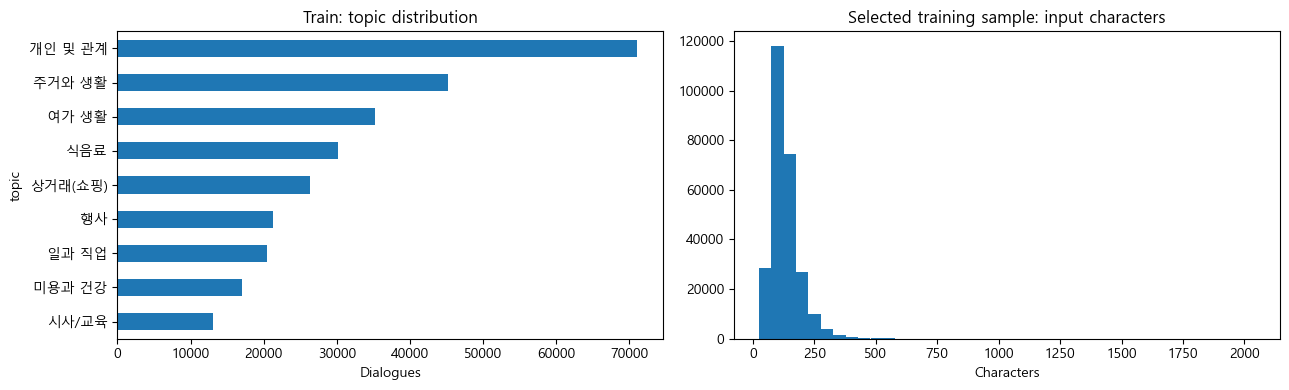

학습 표본 한 건:
 P01: 가고있어??
P02: 지금천왕역 도착했오
P02: 짱 멀어
P02: #@이모티콘#
P02: 1시반10분 타고왔어..
P01: 엄청 멀구마잉
P01: 갔다가 언제와?
P02: 홍대가서 공연보면...
P02: 7시쯤~?
P01: 오호 꽤 늦넵
P02: 7~8시정도될거같아
P01: 비오는데
P01: 뿌엥
P02: 비그쳤오!!
P02: #@이모티콘#
P01: 왔다 안왔다
P01: 하지않오?
P02: 맞아마자 근데 여기 서울끝이라
P02: 여긴 그쳤나봥 
정답: 지금 천왕역에 도착했는데 1시간 10분 걸렸다고 하면서 언제 오냐는 말에 홍대에 가서 공연을 보려면 7시쯤 갈 것이라고 한다.


30

In [6]:
topic_df = pd.DataFrame([{'split':s,'topic':t,'count':n} for (s,t),n in topic_counts.items()])
type_df = pd.DataFrame([{'split':s,'type':t,'count':n} for (s,t),n in type_counts.items()])
display(topic_df.pivot(index='topic',columns='split',values='count'))
display(type_df.pivot(index='type',columns='split',values='count'))
selected_df = pd.concat([pd.DataFrame(rows).assign(split=split)
                        for split,rows in [('train',train_rows),('dev',dev_rows),('final',final_rows)]],ignore_index=True)
display(pd.crosstab([selected_df['topic'],selected_df['type']],selected_df['split']))
length_summary = pd.DataFrame(train_rows)[['input_chars','summary_chars','utterance_count','participant_count']].describe(percentiles=[.5,.9,.95,.99])
display(length_summary)
topic_df.to_csv(RUN_DIR/'topic_counts.csv',index=False,encoding='utf-8-sig')
type_df.to_csv(RUN_DIR/'type_counts.csv',index=False,encoding='utf-8-sig')
length_summary.to_csv(RUN_DIR/'train_sample_lengths.csv',encoding='utf-8-sig')
fig,ax = plt.subplots(1,2,figsize=(13,4))
topic_df.query("split == 'train'").set_index('topic')['count'].sort_values().plot.barh(ax=ax[0])
ax[0].set_title('Train: topic distribution'); ax[0].set_xlabel('Dialogues')
ax[1].hist([r['input_chars'] for r in train_rows],bins=40)
ax[1].set_title('Selected training sample: input characters'); ax[1].set_xlabel('Characters')
plt.tight_layout(); fig.savefig(RUN_DIR/'data_overview.png',dpi=150); plt.show()
print('학습 표본 한 건:\n',train_rows[0]['input'],'\n정답:',train_rows[0]['target'])
del selected_df
gc.collect()

## 코드 07. 토크나이저와 모델 버전 고정

KoBART는 한국어로 사전학습한 약 1.24억 파라미터의 encoder-decoder 모델이다.
실행 시 모델 저장소 commit SHA를 기록하고 토크나이저와 가중치에 같은 버전을 사용한다.
실제 토크나이저의 BOS/EOS/PAD ID를 확인한다. 입력은 BOS+대화+EOS, 정답은 요약+EOS,
디코더 시작은 BOS로 명시한다. 모델 설정 파일의 특수 토큰을 무조건 신뢰하지 않는다.

In [7]:
MODEL_REVISION = HfApi().model_info(CFG['model_id'],revision=CFG['revision']).sha
tokenizer = PreTrainedTokenizerFast.from_pretrained(CFG['model_id'],revision=MODEL_REVISION)
BOS, EOS, PAD = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id
assert all(v is not None for v in [BOS,EOS,PAD]), '특수 토큰을 확인하세요.'
tokenizer.padding_side = 'right'
write_json(RUN_DIR/'model_source.json',{'model_id':CFG['model_id'],'revision':MODEL_REVISION,
                                       'bos':BOS,'eos':EOS,'pad':PAD})
print('모델 commit:',MODEL_REVISION)
print('BOS / EOS / PAD:',BOS,EOS,PAD)
print(tokenizer.tokenize('P01: 내일 저녁에 같이 밥 먹을래?'))

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


모델 commit: f5899cc556216353e23ee36b66fad52b902066c5
BOS / EOS / PAD: 1 1 3
['▁P', '0', '1', ':', '▁내일', '▁저녁', '에', '▁같이', '▁밥', '▁먹을', '래', '?']


c:\Users\use\Documents\KDT17\deeplearning\.venv\lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


## 코드 08. 토큰화·길이 제한·동적 padding

입력 320토큰·정답 80토큰 상한은 시간과 메모리를 줄인다.
truncation_rates.csv에서 잘리는 비율을 확인한다. 긴 입력은 앞 75%와 뒤 25%를 보존해 결론 누락을 줄인다.
최종 점수는 잘리지 않은 원래 정답과 비교한다.
정답 padding은 -100으로 채워 loss에서 제외하고, 각 배치의 최대 길이에만 맞춘다.

In [8]:
def truncate_source(ids):
    available = CFG['max_input_tokens']-2
    if len(ids) <= available:
        return ids
    head = int(available*CFG['input_head_ratio'])
    return ids[:head] + ids[-(available-head):]

def encode_rows(rows):
    encoded = []
    for start in range(0,len(rows),256):
        chunk = rows[start:start+256]
        inputs = tokenizer([r['input'] for r in chunk],add_special_tokens=False)['input_ids']
        targets = tokenizer([r['target'] for r in chunk],add_special_tokens=False)['input_ids']
        for row,src,target in zip(chunk,inputs,targets):
            encoded.append({
                'input_ids':[BOS]+truncate_source(src)+[EOS],
                'labels':target[:CFG['max_target_tokens']-1]+[EOS],
                'source_tokens':len(src)+2,'target_tokens':len(target)+1,
                'dialogue_id':row['dialogue_id'],
            })
    return encoded

train_encoded, dev_encoded = encode_rows(train_rows), encode_rows(dev_rows)
train_selected_n = len(train_rows)
del train_rows
gc.collect()
truncation_table = []
for split,records in [('train',train_encoded),('dev',dev_encoded)]:
    truncation_table.append({
        'split':split,'n':len(records),
        'input_truncation_rate':np.mean([r['source_tokens'] > CFG['max_input_tokens'] for r in records]),
        'target_truncation_rate':np.mean([r['target_tokens'] > CFG['max_target_tokens'] for r in records]),
        'input_tokens_p95':np.percentile([r['source_tokens'] for r in records],95),
    })
display(pd.DataFrame(truncation_table))
pd.DataFrame(truncation_table).to_csv(RUN_DIR/'truncation_rates.csv',index=False)

def collate(records):
    max_src = max(len(r['input_ids']) for r in records)
    max_tgt = max(len(r['labels']) for r in records)
    input_ids = torch.full((len(records),max_src),PAD,dtype=torch.long)
    attention_mask = torch.zeros((len(records),max_src),dtype=torch.long)
    labels = torch.full((len(records),max_tgt),-100,dtype=torch.long)
    for i,r in enumerate(records):
        input_ids[i,:len(r['input_ids'])] = torch.tensor(r['input_ids'])
        attention_mask[i,:len(r['input_ids'])] = 1
        labels[i,:len(r['labels'])] = torch.tensor(r['labels'])
    return {k:v.to(DEVICE) for k,v in {'input_ids':input_ids,'attention_mask':attention_mask,'labels':labels}.items()}

batch_preview = collate(train_encoded[:2])
print({k:tuple(v.shape) for k,v in batch_preview.items()})
print('정답 padding 예시:',batch_preview['labels'][0].tolist())
del batch_preview

,split,n,input_truncation_rate,target_truncation_rate,input_tokens_p95
0,train,265000,0.006106,0.000004,223.0
1,dev,10000,0.006700,0.000000,222.0


{'input_ids': (2, 191), 'attention_mask': (2, 191), 'labels': (2, 27)}
정답 padding 예시: [14446, 14578, 11878, 21413, 17174, 17718, 20809, 24541, 14366, 29324, 16430, 15851, 14075, 24432, 18380, 14554, 15132, 17442, 19981, 14046, 16939, 19580, 12586, 14640, 15751, 19553, 1]


## 코드 09. 한국어 ROUGE와 기준 모델

ROUGE 기본 영어 토크나이저는 한글을 제거할 수 있다.
여기서는 **한글·영문·숫자를 보존하는 어절 토크나이저**와 **한글 글자 토크나이저**를 함께 쓴다.
어절 점수는 정확한 표현 일치를, 글자 점수는 조사·어미가 조금 다른 한국어 표현의 겹침을 보완한다.
문장별 ROUGE F1의 산술평균×100이며 형태소 기준이나 AI Hub 점수와 직접 비교하지 않는다.
기준 모델은 정답을 보지 않고 가장 긴 발화 하나를 뽑는다. 생성 모델의 효과를 확인할 단순 비교 대상이다.

In [9]:
class KoreanWordTokenizer:
    def tokenize(self,text):
        text = unicodedata.normalize('NFC',text).casefold()
        return re.findall(r'[가-힣ㄱ-ㅎㅏ-ㅣa-z0-9]+',text)

class KoreanCharTokenizer:
    def tokenize(self,text):
        text = unicodedata.normalize('NFC',text).casefold()
        return re.findall(r'[가-힣ㄱ-ㅎㅏ-ㅣ]|[a-z0-9]+',text)

word_tokenizer, char_tokenizer = KoreanWordTokenizer(), KoreanCharTokenizer()
word_rouge = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'],use_stemmer=False,tokenizer=word_tokenizer)
char_rouge = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'],use_stemmer=False,tokenizer=char_tokenizer)
def score_pair(reference,prediction):
    result = {f'word_{k}':v.fmeasure*100 for k,v in word_rouge.score(reference,prediction).items()}
    result.update({f'char_{k}':v.fmeasure*100 for k,v in char_rouge.score(reference,prediction).items()})
    return result
def baseline(row):
    return max(row['utterances'],key=len,default='')

assert word_tokenizer.tokenize('안녕 한국어') == ['안녕','한국어']
assert abs(score_pair('내일 저녁 약속','내일 저녁 약속')['word_rougeL']-100) < 1e-6
dev_baseline_scores = pd.DataFrame([score_pair(r['target'],baseline(r)) for r in dev_rows])
print('개발셋 기준 모델 점수 — 최종 평가가 아님')
display(dev_baseline_scores.mean().to_frame('Longest utterance / dev'))

개발셋 기준 모델 점수 — 최종 평가가 아님


,Longest utterance / dev
word_rouge1,5.901409
word_rouge2,1.608877
word_rougeL,5.811450
char_rouge1,25.553918
char_rouge2,13.159259
char_rougeL,21.789230


## 코드 10. 모델과 optimizer 준비

BartForConditionalGeneration으로 생성 요약용 모델을 만든다.
원 저장소는 BartModel 형태이므로 생성 헤드 관련 초기화 안내가 나올 수 있다.
사전학습 가중치와 공유 단어 임베딩을 활용하고 아래 학습으로 요약 과제에 맞춘다.
GPU에서는 gradient checkpointing과 BF16(미지원 시 FP16)을 사용한다.
checkpointing은 일부 중간 값을 재계산하므로 메모리를 아끼는 대신 연산량이 늘어난다.

In [10]:
model = BartForConditionalGeneration.from_pretrained(
    CFG['model_id'],revision=MODEL_REVISION,use_safetensors=True,attn_implementation='eager',
)
model.config.bos_token_id = BOS
model.config.eos_token_id = EOS
model.config.pad_token_id = PAD
model.config.decoder_start_token_id = BOS
model.config.forced_eos_token_id = EOS
model.config.forced_bos_token_id = None
model.config.use_cache = False
model.generation_config = GenerationConfig(
    bos_token_id=BOS,eos_token_id=EOS,pad_token_id=PAD,decoder_start_token_id=BOS,
    forced_eos_token_id=EOS,max_new_tokens=CFG['max_new_tokens'],num_beams=CFG['num_beams'],do_sample=False,
)
model.to(DEVICE)

# 긴 학습 전에 실제 전처리 배치로 forward가 되는지와 loss 유한성을 확인한다.
model.eval()
with torch.inference_mode():
    sanity_batch = collate(train_encoded[:min(2,len(train_encoded))])
    with amp_context():
        sanity_loss = float(model(**sanity_batch).loss.detach().cpu())
assert math.isfinite(sanity_loss),f'사전 검증 loss가 유한하지 않습니다: {sanity_loss}'
print(f'학습 사전 검증 통과 | loss={sanity_loss:.4f}')
del sanity_batch
model.train()
if cuda_ok:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
optimizer = torch.optim.AdamW(model.parameters(),lr=CFG['learning_rate'],
                             weight_decay=CFG['weight_decay'],foreach=False)
max_updates = min(CFG['max_steps'],math.ceil(len(train_encoded)/CFG['effective_batch'])*CFG['max_epochs'])
scheduler = get_linear_schedule_with_warmup(
    optimizer,num_warmup_steps=max(1,int(max_updates*CFG['warmup_ratio'])),num_training_steps=max_updates,
)
scaler = torch.amp.GradScaler('cuda',enabled=USE_FP16)
dev_loss_records = random.Random(SEED+30).sample(dev_encoded,min(CFG['dev_loss_n'],len(dev_encoded)))
parameter_count = sum(p.numel() for p in model.parameters())
print(f'파라미터: {parameter_count:,} | 최대 업데이트: {max_updates:,} | BF16: {USE_BF16} / FP16: {USE_FP16}')

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


학습 사전 검증 통과 | loss=13.4263
파라미터: 123,859,968 | 최대 업데이트: 33,126 | BF16: True / FP16: False


## 코드 11. 시간 제한·메모리 재시도·개발 평가 함수

한 업데이트에 쓰는 16개 대화를 작은 배치로 나눠 gradient를 누적한다.
forward/backward 메모리가 부족하면 그 업데이트의 gradient를 버리고 배치를 반으로 줄여 재계산한다.
배치 1에서도 실패하면 중단한다. optimizer 업데이트 도중 실패는 일부 변경 가능성이 있어 재시도하지 않는다.
개발 평가는 생성 대신 loss만 계산하며, 고정 표본 2,048건의 토큰 가중 평균을 사용한다.
시간 부족으로 개발 표본을 끝까지 평가하지 못하면 그 loss로 모델을 선택하지 않는다.

In [11]:
@torch.inference_mode()
def evaluate_dev_loss(deadline):
    model.eval()
    total_loss, total_tokens, completed = 0.0, 0, 0
    for start in range(0,len(dev_loss_records),CFG['dev_loss_batch']):
        if time.monotonic() >= deadline:
            break
        records = dev_loss_records[start:start+CFG['dev_loss_batch']]
        batch = collate(records)
        with amp_context():
            output = model(**batch)
        count = int((batch['labels'] != -100).sum().item())
        loss_value = float(output.loss.item())
        if not math.isfinite(loss_value):
            raise FloatingPointError('개발 loss가 NaN/Inf입니다.')
        total_loss += loss_value*count; total_tokens += count; completed += len(records)
        del batch, output
    model.train()
    return (total_loss/total_tokens if total_tokens else None), completed == len(dev_loss_records)

def backward_update(records,micro_batch,deadline):
    while True:
        optimizer.zero_grad(set_to_none=True)
        average_loss = 0.0
        batch = output = loss = None
        try:
            for start in range(0,len(records),micro_batch):
                if time.monotonic() >= deadline:
                    optimizer.zero_grad(set_to_none=True)
                    return None,micro_batch,'time_budget'
                chunk = records[start:start+micro_batch]
                batch = collate(chunk)
                with amp_context():
                    output = model(**batch)
                    loss = output.loss
                if not torch.isfinite(loss).item():
                    raise FloatingPointError('학습 loss가 NaN/Inf입니다.')
                weight = len(chunk)/len(records)
                average_loss += float(loss.detach().item())*weight
                scaler.scale(loss*weight).backward()
                del batch,output,loss
                batch = output = loss = None
            return average_loss,micro_batch,None
        except torch.cuda.OutOfMemoryError:
            pass
        finally:
            del batch,output,loss
        # except 바깥에서 정리하여 traceback이 GPU tensor를 붙잡지 않도록 한다.
        optimizer.zero_grad(set_to_none=True)
        gc.collect()
        if cuda_ok:
            torch.cuda.empty_cache()
        if micro_batch == 1:
            return None,micro_batch,'out_of_memory_at_batch_1'
        micro_batch = max(1,micro_batch//2)
        print(f'OOM: micro_batch={micro_batch}로 같은 업데이트를 다시 계산합니다.')

def save_best_model(path):
    model.save_pretrained(path,safe_serialization=True)
    tokenizer.save_pretrained(path)

def shuffled_indices(n):
    rng = np.random.default_rng(SEED)
    while True:
        yield from rng.permutation(n).tolist()

## 코드 12. 학습 — 가장 오래 걸리는 셀

최대 33,126회 업데이트(26.5만 건 표본의 약 2epoch), 개발 loss 4번 연속 미개선 시 조기 종료한다.
매 100회 진행률·loss·시간 추정을 출력한다. 2,500회마다 개발 loss를 계산하고 최선 모델을 저장한다.
셀 진입 시 남은 전체 예산과 학습 상한 중 작은 쪽을 시간 제한으로 삼는다.
수동 중단 시 가능한 경우 마지막 모델을 저장한다. 프로세스 강제 종료는 저장을 보장하지 않는다.
가중치만 저장하므로 optimizer/난수 상태까지 포함한 정확한 학습 재개는 제공하지 않는다.

In [12]:
training_start = time.monotonic()
train_deadline = min(training_start+CFG['train_hours']*3600,
                     GLOBAL_DEADLINE-CFG['post_train_reserve_minutes']*60)
BEST_MODEL_DIR = RUN_DIR/'best_model'
LAST_MODEL_DIR = RUN_DIR/'last_model'
history = []
best_dev_loss, best_step, stale = float('inf'), None, 0
completed_steps, current_micro = 0, CFG['micro_batch']
stop_reason = 'max_updates'
indices = shuffled_indices(len(train_encoded))
print('학습에 남은 시간(분):',round(max(0,train_deadline-time.monotonic())/60,1))
model.train()
try:
    for step in range(1,max_updates+1):
        if time.monotonic() >= train_deadline:
            stop_reason = 'time_budget'; break
        records = [train_encoded[next(indices)] for _ in range(CFG['effective_batch'])]
        loss_value,current_micro,reason = backward_update(records,current_micro,train_deadline)
        if reason:
            stop_reason = reason; break
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        if not torch.isfinite(grad_norm).item():
            if USE_FP16:
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True)
                print(f'step {step}: FP16 gradient overflow, update skipped')
                continue
            raise FloatingPointError('gradient가 NaN/Inf입니다.')
        scaler.step(optimizer); scaler.update(); scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        completed_steps += 1
        elapsed = time.monotonic()-training_start
        log = {'step':step,'updates_completed':completed_steps,'train_loss':loss_value,
               'learning_rate':scheduler.get_last_lr()[0],'elapsed_minutes':elapsed/60,'micro_batch':current_micro}
        if step % CFG['eval_every'] == 0 or step == max_updates:
            dev_loss,full = evaluate_dev_loss(min(train_deadline,time.monotonic()+180))
            log.update(dev_loss=dev_loss if full else None,dev_eval_complete=full)
            if full and dev_loss is not None:
                if dev_loss < best_dev_loss-1e-4:
                    best_dev_loss,best_step,stale = dev_loss,step,0
                    save_best_model(BEST_MODEL_DIR)
                else:
                    stale += 1
                print(f'step {step}: dev loss={dev_loss:.4f}, best={best_step}, patience={stale}/{CFG["patience"]}')
        history.append(log)
        if step == 1 or step % 100 == 0:
            eta = (max_updates-step)*(elapsed/completed_steps)/60
            print(f'{step}/{max_updates} | loss={loss_value:.4f} | 경과={elapsed/60:.1f}분 | 끝까지 추정={eta:.1f}분')
            pd.DataFrame(history).to_csv(RUN_DIR/'training_history.csv',index=False)
        if stale >= CFG['patience']:
            stop_reason = 'early_stopping'; break
except KeyboardInterrupt:
    stop_reason = 'keyboard_interrupt'
    print('사용자 중단: 저장이 완료되면 다음 셀부터 진행할 수 있습니다.')
except torch.cuda.OutOfMemoryError:
    stop_reason = 'out_of_memory_during_update_or_eval'
    print('optimizer/평가 중 메모리 부족. 정상 완료 학습으로 해석하지 마세요.')
except Exception:
    stop_reason = 'error'
    raise
finally:
    optimizer.zero_grad(set_to_none=True)
    gc.collect()
    if cuda_ok:
        torch.cuda.empty_cache()
    model.config.use_cache = True
    model.save_pretrained(LAST_MODEL_DIR,safe_serialization=True)
    tokenizer.save_pretrained(LAST_MODEL_DIR)
    pd.DataFrame(history).to_csv(RUN_DIR/'training_history.csv',index=False)
    train_status = {'profile':PROFILE,'completed_updates':completed_steps,'stop_reason':stop_reason,
                    'best_step':best_step,'best_dev_loss':best_dev_loss if math.isfinite(best_dev_loss) else None,
                    'train_minutes':(time.monotonic()-training_start)/60,'actual_micro_batch':current_micro}
    write_json(RUN_DIR/'training_status.json',train_status)
display(train_status)
if completed_steps == 0:
    print('주의: 학습 업데이트가 0회입니다. 이후 결과는 미세조정 성능으로 보고하지 마세요.')

학습에 남은 시간(분): 345.0
1/33126 | loss=11.1698 | 경과=0.0분 | 끝까지 추정=535.0분
100/33126 | loss=4.0694 | 경과=1.0분 | 끝까지 추정=339.1분
200/33126 | loss=2.8537 | 경과=2.0분 | 끝까지 추정=332.3분
300/33126 | loss=2.6393 | 경과=3.0분 | 끝까지 추정=332.3분
400/33126 | loss=2.7567 | 경과=4.1분 | 끝까지 추정=331.4분
500/33126 | loss=2.3767 | 경과=5.1분 | 끝까지 추정=330.1분
600/33126 | loss=2.5682 | 경과=6.1분 | 끝까지 추정=329.9분
700/33126 | loss=2.6028 | 경과=7.1분 | 끝까지 추정=329.4분
800/33126 | loss=2.6138 | 경과=8.1분 | 끝까지 추정=328.6분
900/33126 | loss=2.5413 | 경과=9.2분 | 끝까지 추정=327.7분
1000/33126 | loss=2.3099 | 경과=10.2분 | 끝까지 추정=326.9분
1100/33126 | loss=2.7173 | 경과=11.2분 | 끝까지 추정=326.5분
1200/33126 | loss=2.2755 | 경과=12.3분 | 끝까지 추정=326.0분
1300/33126 | loss=2.6518 | 경과=13.3분 | 끝까지 추정=325.1분
1400/33126 | loss=2.4330 | 경과=14.3분 | 끝까지 추정=324.3분
1500/33126 | loss=2.4806 | 경과=15.3분 | 끝까지 추정=323.4분
1600/33126 | loss=2.3727 | 경과=16.4분 | 끝까지 추정=322.6분
1700/33126 | loss=2.4201 | 경과=17.4분 | 끝까지 추정=321.4분
1800/33126 | loss=2.3032 | 경과=18.4분 | 끝까지 추정=320.4분
1900/33126 | 

Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


step 2500: dev loss=2.1803, best=2500, patience=0/4
2500/33126 | loss=2.3318 | 경과=25.6분 | 끝까지 추정=313.2분
2600/33126 | loss=2.3168 | 경과=26.7분 | 끝까지 추정=313.3분
2700/33126 | loss=2.2328 | 경과=27.7분 | 끝까지 추정=312.3분
2800/33126 | loss=2.5241 | 경과=28.7분 | 끝까지 추정=311.2분
2900/33126 | loss=2.2209 | 경과=29.7분 | 끝까지 추정=310.0분
3000/33126 | loss=2.0744 | 경과=30.8분 | 끝까지 추정=308.9분
3100/33126 | loss=1.9058 | 경과=31.8분 | 끝까지 추정=307.8분
3200/33126 | loss=2.5148 | 경과=32.8분 | 끝까지 추정=306.6분
3300/33126 | loss=2.0382 | 경과=33.8분 | 끝까지 추정=305.6분
3400/33126 | loss=2.5059 | 경과=34.8분 | 끝까지 추정=304.5분
3500/33126 | loss=2.3350 | 경과=35.8분 | 끝까지 추정=303.4분
3600/33126 | loss=2.1571 | 경과=36.9분 | 끝까지 추정=302.4분
3700/33126 | loss=2.3782 | 경과=37.9분 | 끝까지 추정=301.4분
3800/33126 | loss=2.0489 | 경과=38.9분 | 끝까지 추정=300.4분
3900/33126 | loss=2.2619 | 경과=39.9분 | 끝까지 추정=299.4분
4000/33126 | loss=2.2387 | 경과=41.0분 | 끝까지 추정=298.4분
4100/33126 | loss=2.0171 | 경과=42.0분 | 끝까지 추정=297.5분
4200/33126 | loss=2.3113 | 경과=43.0분 | 끝까지 추정=296.5분
4300/33126 |

Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


step 5000: dev loss=2.0596, best=5000, patience=0/4
5000/33126 | loss=2.4419 | 경과=51.2분 | 끝까지 추정=288.2분
5100/33126 | loss=2.4824 | 경과=81.5분 | 끝까지 추정=447.9분
5200/33126 | loss=2.1046 | 경과=82.5분 | 끝까지 추정=443.2분
5300/33126 | loss=1.8517 | 경과=83.5분 | 끝까지 추정=438.6분
5400/33126 | loss=2.0271 | 경과=84.6분 | 끝까지 추정=434.3분
5500/33126 | loss=2.0416 | 경과=85.6분 | 끝까지 추정=430.0분
5600/33126 | loss=2.0103 | 경과=86.6분 | 끝까지 추정=425.8분
5700/33126 | loss=2.1903 | 경과=87.7분 | 끝까지 추정=421.8분
5800/33126 | loss=2.0730 | 경과=88.7분 | 끝까지 추정=417.8분
5900/33126 | loss=2.2144 | 경과=89.7분 | 끝까지 추정=413.9분
6000/33126 | loss=2.1738 | 경과=90.7분 | 끝까지 추정=410.2분
6100/33126 | loss=2.0080 | 경과=91.7분 | 끝까지 추정=406.5분
6200/33126 | loss=2.0792 | 경과=92.8분 | 끝까지 추정=402.9분
6300/33126 | loss=2.0940 | 경과=93.8분 | 끝까지 추정=399.4분
6400/33126 | loss=2.6295 | 경과=94.8분 | 끝까지 추정=396.0분
6500/33126 | loss=2.3994 | 경과=95.8분 | 끝까지 추정=392.6분
6600/33126 | loss=1.8947 | 경과=96.9분 | 끝까지 추정=389.3분
6700/33126 | loss=2.2971 | 경과=97.9분 | 끝까지 추정=386.1분
6800/33126 |

Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


... (9 outputs left out)

Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


step 20000: dev loss=1.7754, best=20000, patience=0/4
20000/33126 | loss=1.7780 | 경과=323.8분 | 끝까지 추정=212.5분
20100/33126 | loss=1.6725 | 경과=325.2분 | 끝까지 추정=210.7분
20200/33126 | loss=1.8522 | 경과=326.4분 | 끝까지 추정=208.9분
20300/33126 | loss=1.6667 | 경과=327.8분 | 끝까지 추정=207.1분
20400/33126 | loss=1.5748 | 경과=329.0분 | 끝까지 추정=205.2분
20500/33126 | loss=1.6817 | 경과=330.3분 | 끝까지 추정=203.4분
20600/33126 | loss=1.6174 | 경과=331.5분 | 끝까지 추정=201.6분
20700/33126 | loss=1.7471 | 경과=332.8분 | 끝까지 추정=199.8분
20800/33126 | loss=1.5711 | 경과=334.2분 | 끝까지 추정=198.0분
20900/33126 | loss=1.7584 | 경과=335.5분 | 끝까지 추정=196.2분
21000/33126 | loss=1.5456 | 경과=336.8분 | 끝까지 추정=194.5분
21100/33126 | loss=1.6514 | 경과=338.2분 | 끝까지 추정=192.7분
21200/33126 | loss=1.5640 | 경과=339.5분 | 끝까지 추정=191.0분
21300/33126 | loss=1.8212 | 경과=340.8분 | 끝까지 추정=189.2분
21400/33126 | loss=1.9185 | 경과=342.1분 | 끝까지 추정=187.5분
21500/33126 | loss=1.4904 | 경과=343.4분 | 끝까지 추정=185.7분
21600/33126 | loss=1.7686 | 경과=344.7분 | 끝까지 추정=183.9분


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


{'profile': 'gpu_7h',
 'completed_updates': 21628,
 'stop_reason': 'time_budget',
 'best_step': 20000,
 'best_dev_loss': 1.7754342486307622,
 'train_minutes': 345.0260499999999,
 'actual_micro_batch': 2}

## 코드 13. 학습 곡선과 최종 모델 고정

train loss가 내려가도 요약의 사실성이 좋아졌다고 단정할 수 없다. 실제 예측과 함께 본다.
개발 평가를 끝낸 가중치가 있으면 최선 loss 모델을 선택하고, 없으면 마지막 가중치를 사용했다고 기록한다.
모델 선택 이후 공식 Validation을 평가하며, 그 결과에 맞춰 튜닝하면 독립적인 최종 평가가 아니게 된다.

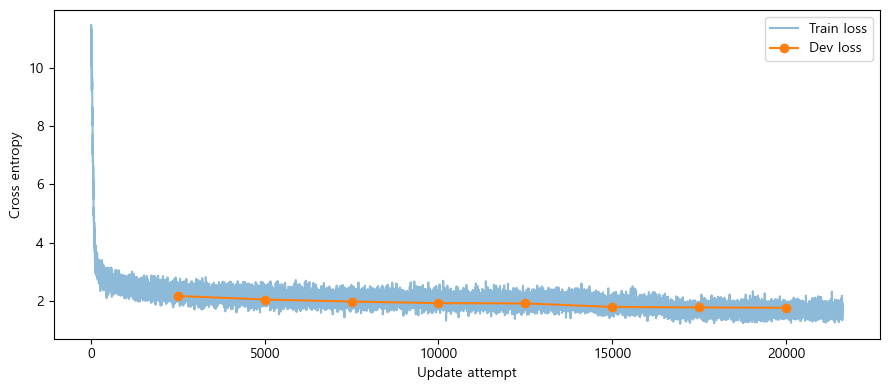

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


개발 loss 최선 가중치 / step 20000 
최종 모델 저장: C:\Users\use\Documents\KDT17\팀프로젝트4\output\notebook_runs\20260920_160110_435084\final_model


In [13]:
history_df = pd.DataFrame(history)
if not history_df.empty:
    fig,ax = plt.subplots(figsize=(9,4))
    ax.plot(history_df['step'],history_df['train_loss'],alpha=.5,label='Train loss')
    if 'dev_loss' in history_df:
        evaluated = history_df.dropna(subset=['dev_loss'])
        ax.plot(evaluated['step'],evaluated['dev_loss'],marker='o',label='Dev loss')
    ax.set_xlabel('Update attempt'); ax.set_ylabel('Cross entropy'); ax.legend()
    plt.tight_layout(); fig.savefig(RUN_DIR/'training_curve.png',dpi=150); plt.show()
del optimizer,scheduler,scaler,train_encoded,dev_encoded,dev_loss_records
gc.collect()
if cuda_ok:
    torch.cuda.empty_cache()
if BEST_MODEL_DIR.exists():
    del model
    gc.collect()
    if cuda_ok:
        torch.cuda.empty_cache()
    model = BartForConditionalGeneration.from_pretrained(
        BEST_MODEL_DIR,local_files_only=True,use_safetensors=True,attn_implementation='eager',
    ).to(DEVICE)
    selection = f'개발 loss 최선 가중치 / step {best_step}'
else:
    selection = '개발 평가 완료본 없음: 마지막 가중치 사용'
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()
FINAL_MODEL_DIR = RUN_DIR/'final_model'
model.save_pretrained(FINAL_MODEL_DIR,safe_serialization=True)
tokenizer.save_pretrained(FINAL_MODEL_DIR)
write_json(RUN_DIR/'selection.json',{'selection':selection,'training':train_status})
print(selection,'\n최종 모델 저장:',FINAL_MODEL_DIR)

## 코드 14. 개발셋에서 생성 설정 선택 → 공식 Validation 전체 평가

모델 가중치는 개발 loss로 골랐지만, 생성 시 beam 수와 길이 패널티도 결과에 영향을 준다.
개발 데이터 500건에서 greedy와 두 beam 설정을 비교하고 어절/글자 ROUGE-L 평균이 가장 높은 설정을 고정한다.
그 뒤 공식 Validation 전체를 딱 한 번 생성한다. Validation 결과를 보고 설정을 다시 고르면 최종 평가가 아니다.

시간 제한으로 일부만 끝나면 실제 완료 건수와 사유를 기록한다. 입력 잘림·생성 길이 제한·빈 출력도 보존한다.
공식 Test가 없으므로 결과 명칭은 **공식 Validation 전체 평가**다.

In [14]:
def input_batch(texts):
    raw = tokenizer(texts,add_special_tokens=False)['input_ids']
    capped = [[BOS]+truncate_source(ids)+[EOS] for ids in raw]
    padded = tokenizer.pad({'input_ids':capped},padding=True,return_tensors='pt')
    batch = {k:v.to(DEVICE) for k,v in padded.items() if k in ['input_ids','attention_mask']}
    return batch,[len(ids)+2 for ids in raw]

@torch.inference_mode()
def generate_texts(texts,decode_config,seconds_limit=120):
    batch,original_lengths = input_batch(texts)
    kwargs = dict(max_new_tokens=CFG['max_new_tokens'],do_sample=False,no_repeat_ngram_size=3,
                  max_time=max(1.0,seconds_limit),use_cache=True,**decode_config)
    with amp_context():
        generated = model.generate(**batch,**kwargs)
    token_lists = generated.cpu().tolist()
    predictions = tokenizer.batch_decode(generated,skip_special_tokens=True)
    flags = []
    for seq,original_len in zip(token_lists,original_lengths):
        tail = seq[1:]
        end_pos = tail.index(EOS)+1 if EOS in tail else len(tail)
        flags.append({'input_truncated':original_len > CFG['max_input_tokens'],
                      'generation_limit_hit':EOS not in tail or end_pos >= CFG['max_new_tokens']})
    return [clean_space(p) for p in predictions],flags

def generate_rows(rows,decode_config,deadline,label):
    outputs,offset,batch_size = [],0,CFG['generation_batch']
    stop_reason = 'all_rows'
    while offset < len(rows):
        remaining = deadline-time.monotonic()
        if remaining <= 1:
            stop_reason = 'time_budget'; break
        chunk = rows[offset:offset+batch_size]
        try:
            predictions,flags = generate_texts([r['input'] for r in chunk],decode_config,min(120,remaining))
        except torch.cuda.OutOfMemoryError:
            gc.collect()
            if cuda_ok:
                torch.cuda.empty_cache()
            if batch_size == 1:
                stop_reason = 'out_of_memory'; break
            batch_size = max(1,batch_size//2)
            print(label,'OOM → 생성 배치',batch_size)
            continue
        outputs.extend([{'prediction':p,**f} for p,f in zip(predictions,flags)])
        offset += len(chunk)
        if offset % 1000 == 0 or offset == len(rows):
            print(f'{label}: {offset}/{len(rows)}')
    return outputs,stop_reason,batch_size

DECODE_CANDIDATES = {
    'greedy':{'num_beams':1},
    'beam4':{'num_beams':4,'length_penalty':1.0,'early_stopping':True},
    'beam4_short':{'num_beams':4,'length_penalty':0.8,'early_stopping':True},
}
dev_generation_rows = random.Random(SEED+70).sample(dev_rows,min(500,len(dev_rows)))
decode_deadline = min(time.monotonic()+10*60,GLOBAL_DEADLINE-35*60)
decode_trials = []
for name,decode_config in DECODE_CANDIDATES.items():
    trial_started = time.monotonic()
    outputs,reason,_ = generate_rows(dev_generation_rows,decode_config,decode_deadline,f'개발 {name}')
    trial_seconds = time.monotonic()-trial_started
    if len(outputs) != len(dev_generation_rows):
        decode_trials.append({'name':name,'complete':False,'n':len(outputs),'stop_reason':reason,
                              'trial_seconds':trial_seconds})
        break
    scores = pd.DataFrame([score_pair(row['target'],out['prediction'])
                           for row,out in zip(dev_generation_rows,outputs)])
    trial = {'name':name,'complete':True,'n':len(outputs),'stop_reason':reason,
             'trial_seconds':trial_seconds,
             'projected_full_minutes':trial_seconds/len(outputs)*len(final_rows)/60,
             **scores.mean().to_dict()}
    trial['selection_score'] = (trial['word_rougeL']+trial['char_rougeL'])/2
    decode_trials.append(trial)
decode_df = pd.DataFrame(decode_trials)
complete_trials = (decode_df[decode_df['complete'].fillna(False).astype(bool)]
                   if not decode_df.empty else pd.DataFrame())
if complete_trials.empty:
    selected_decode_name = 'greedy'
else:
    generation_budget_for_selection = CFG['final_generation_minutes']*0.9
    eligible = complete_trials[
        complete_trials['projected_full_minutes'] <= generation_budget_for_selection
    ]
    if eligible.empty:
        eligible = complete_trials.sort_values('projected_full_minutes').head(1)
    selected_decode_name = eligible.sort_values('selection_score',ascending=False).iloc[0]['name']
selected_decode = DECODE_CANDIDATES[selected_decode_name]
for key,value in selected_decode.items():
    setattr(model.generation_config,key,value)
model.generation_config.no_repeat_ngram_size = 3
model.generation_config.save_pretrained(FINAL_MODEL_DIR)
decode_df.to_csv(RUN_DIR/'decode_tuning.csv',index=False,encoding='utf-8-sig')
write_json(RUN_DIR/'selected_decode.json',{'name':selected_decode_name,'config':selected_decode,
                                          'trials':decode_trials,'selection_data':'development 500 max'})
display(decode_df)
print('선택한 생성 설정:',selected_decode_name,selected_decode)
del dev_generation_rows

generation_started = time.monotonic()
generation_deadline = min(generation_started+CFG['final_generation_minutes']*60,GLOBAL_DEADLINE-5*60)
generated_rows,evaluation_stop,actual_generation_batch = generate_rows(
    final_rows,selected_decode,generation_deadline,'공식 Validation')
evaluation_records = []
with open(RUN_DIR/'final_predictions.jsonl','w',encoding='utf-8') as stream:
    for row,out in zip(final_rows,generated_rows):
        prediction,base = out['prediction'],baseline(row)
        result = {k:row[k] for k in ['dialogue_id','topic','type','input','target']}
        pred_words = word_tokenizer.tokenize(prediction)
        input_words = set(word_tokenizer.tokenize(row['input']))
        novel_ratio = np.mean([token not in input_words for token in pred_words]) if pred_words else 0.0
        result.update(prediction=prediction,baseline=base,**{k:v for k,v in out.items() if k!='prediction'},
                      empty_prediction=not bool(prediction),novel_word_ratio=float(novel_ratio),
                      **{f'model_{k}':v for k,v in score_pair(row['target'],prediction).items()},
                      **{f'baseline_{k}':v for k,v in score_pair(row['target'],base).items()})
        evaluation_records.append(result)
        stream.write(json.dumps(result,ensure_ascii=False)+'\n')
evaluation_status = {'selected_n':len(final_rows),'evaluated_n':len(evaluation_records),
                     'complete':len(evaluation_records)==len(final_rows),'stop_reason':evaluation_stop,
                     'generation_minutes':(time.monotonic()-generation_started)/60,
                     'generation_batch':actual_generation_batch,'decode':selected_decode_name,
                     'label':'공식 Validation 전체 평가 (공식 Test 아님)'}
write_json(RUN_DIR/'evaluation_status.json',evaluation_status)
predictions_df = pd.DataFrame(evaluation_records)
predictions_df.to_csv(RUN_DIR/'final_predictions.csv',index=False,encoding='utf-8-sig')
display(evaluation_status)

You're using a PreTrainedTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


개발 greedy: 500/500
개발 beam4: 500/500
개발 beam4_short: 500/500


,name,complete,n,stop_reason,trial_seconds,projected_full_minutes,word_rouge1,word_rouge2,word_rougeL,char_rouge1,char_rouge2,char_rougeL,selection_score
0,greedy,True,500,all_rows,23.766,27.730169,24.689331,9.981157,23.622756,50.349764,31.278382,43.744516,33.683636
1,beam4,True,500,all_rows,45.515,53.106902,25.843976,11.516256,24.849939,50.874015,32.324298,44.481795,34.665867
2,beam4_short,True,500,all_rows,42.485,49.571498,25.706163,11.378086,24.703468,50.500526,32.135064,44.343811,34.523639


선택한 생성 설정: greedy {'num_beams': 1}
공식 Validation: 1000/35004
공식 Validation: 2000/35004
공식 Validation: 3000/35004
공식 Validation: 4000/35004
공식 Validation: 5000/35004
공식 Validation: 6000/35004
공식 Validation: 7000/35004
공식 Validation: 8000/35004
공식 Validation: 9000/35004
공식 Validation: 10000/35004
공식 Validation: 11000/35004
공식 Validation: 12000/35004
공식 Validation: 13000/35004
공식 Validation: 14000/35004
공식 Validation: 15000/35004
공식 Validation: 16000/35004
공식 Validation: 17000/35004
공식 Validation: 18000/35004
공식 Validation: 19000/35004
공식 Validation: 20000/35004
공식 Validation: 21000/35004
공식 Validation: 22000/35004
공식 Validation: 23000/35004
공식 Validation: 24000/35004
공식 Validation: 25000/35004
공식 Validation: 26000/35004
공식 Validation: 27000/35004
공식 Validation: 28000/35004
공식 Validation: 29000/35004
공식 Validation: 30000/35004
공식 Validation: 31000/35004
공식 Validation: 32000/35004
공식 Validation: 33000/35004
공식 Validation: 34000/35004
공식 Validation: 35000/35004
공식 Validation: 35004/35004


{'selected_n': 35004,
 'evaluated_n': 35004,
 'complete': True,
 'stop_reason': 'all_rows',
 'generation_minutes': 30.15051666666647,
 'generation_batch': 4,
 'decode': 'greedy',
 'label': '공식 Validation 전체 평가 (공식 Test 아님)'}

## 코드 15. 성능 비교·주제별 결과·오류 분석

ROUGE는 표현의 겹침을 보므로 사실성이나 화자 정확성을 보장하지 않는다.
낮은 점수 사례와 무작위 사례를 함께 읽고 원문에 없는 인물·시간·행동을 생성했는지 확인한다.
소수 주제/토론 표본의 평균을 전체 성능으로 일반화하지 않는다.
human_review.csv는 낮은 점수 20건과 무작위 최대 30건을 합친 **오류 분석용 표본**이다.
대표 성능 추정용 표본이 아니며, 사실성·핵심 내용·자연스러움을 1~5점으로 직접 기록한다.

,method,n,word_rouge1,word_rouge2,word_rougeL,char_rouge1,char_rouge2,char_rougeL
0,Longest utterance,35004,5.977549,1.620292,5.882958,25.911386,13.555053,22.233241
1,Fine-tuned KoBART,35004,24.304065,9.679727,23.186550,49.837495,30.986204,43.007148


,topic,n,model_word_rougeL,model_char_rougeL,baseline_word_rougeL,input_truncation_rate
0,개인 및 관계,8892,23.863251,42.853745,6.007821,0.008097
1,미용과 건강,2134,23.583914,42.737280,6.041701,0.007498
2,상거래(쇼핑),3288,21.653515,41.700326,5.303950,0.004562
3,시사/교육,1640,23.115227,43.392981,6.437088,0.008537
4,식음료,3773,23.050936,44.636540,5.679522,0.004506
5,여가 생활,4407,22.501950,43.227781,6.062313,0.005446
6,일과 직업,2554,23.280949,42.848463,5.837761,0.010180
7,주거와 생활,5648,23.495276,43.151210,6.116774,0.003541
8,행사,2668,23.125201,42.285870,5.252504,0.007121


,type,n,model_word_rougeL,model_char_rougeL,baseline_word_rougeL,input_truncation_rate
0,일상 대화,34816,23.246806,43.054701,5.899470,0.006348
1,토론 대화,188,12.027663,34.200848,2.825066,0.010638


,rate
input_truncated,0.006371
generation_limit_hit,0.000000
empty_prediction,0.000000
novel_word_ratio,0.752201


,input,target,prediction,baseline,model_word_rougeL,model_char_rougeL
0,P01: 나 지금 뉴스 틀아놨어서\nP01: 보는데\nP01: ㅁㅊ 산부인과에서\n...,산부인과에서 일어난 수술 사고 뉴스에 대해 이야기를 나눈다.,뉴스를 틀어서 보는데 영양제를 맞으러 온 임산부한테 낙태 수술을 했다고 해서 화가 난다.,살인아니냐고 개화난다 아!!!!!!!!!,0.0,22.950820
15,P01: 나 오늘\nP01: 이케아 갔다가\nP01: 꿈의 주방을 보았어\nP02:...,오늘 이케아에 갔다가 꿈의 주방을 보았다.,이케아에서 점제방을 봤는데 너무 밝고 아름다웠다.,이런 쪽이 더 잘 맞는거 같아,0.0,36.842105
17,P01: ㅠㅠㅠㅠㅠ노동노동\nP01: 하지만 이러한 노동도 평생할 수 업다는 거.....,평생직장이 없고 길면 마흔까지만 일을 시켜준다.,정년이 60이라고 하지만 이미 마흔이면 끝이다.,할매되서 일할 자신도없고 일찍 죽을 자신도없고 하니까 저축을할수밖에 ㅠ,0.0,25.641026
20,P01: 쌤소나이트 사 면세가로\nP02: 왜말바뀌었어\nP01: 오늘은 만다리나덕...,면세가격으로 구매할 만다리나덕과 샘소나이트(쌤소) 가방의 특징을 비교한다.,쌤소나이트에서 만다리나덕을 면세로 사기로 했다.,만다리나덕 가격좋으면 사는게나을듯 지난번 은 as면에서 쌤소 말했는데 좀 흔한듯,0.0,26.415094
22,P01: 말레피센트1 보는중인데\nP01: 안젤리나졸리#@기타# 멋있어\nP02: ...,유명한 외국 영화 시리즈 스토리를 공유하고 개인적인 견해로 평가하고있다.,말레피센트 1은 유치한데 안젤리나 졸리가 멋있고 2는 스토리가 나올 게 없어 보이는...,내용은 #@기타#유치한데 안젤리나졸리멋있어,0.0,24.489796


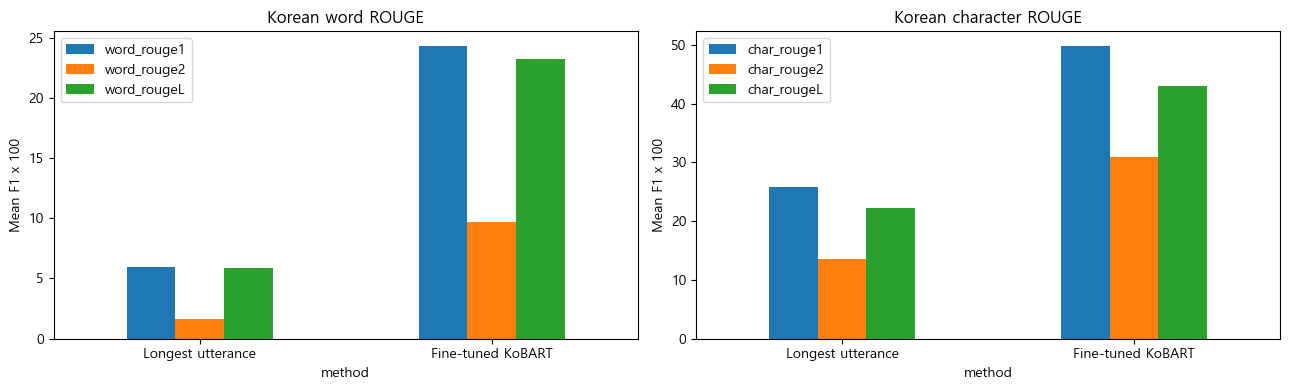

In [15]:
metric_names = ['word_rouge1','word_rouge2','word_rougeL','char_rouge1','char_rouge2','char_rougeL']
comparison = pd.DataFrame()
if predictions_df.empty:
    print('생성 결과가 없어 점수를 만들지 않습니다. evaluation_status.json을 확인하세요.')
else:
    model_label = 'Fine-tuned KoBART' if completed_steps > 0 else 'KoBART (no training updates)'
    comparison = pd.DataFrame([
        {'method':name,'n':len(predictions_df),**{k:predictions_df[f'{prefix}_{k}'].mean() for k in metric_names}}
        for name,prefix in [('Longest utterance','baseline'),(model_label,'model')]
    ])
    display(comparison)
    comparison.to_csv(RUN_DIR/'metric_comparison.csv',index=False,encoding='utf-8-sig')
    for group in ['topic','type']:
        grouped = predictions_df.groupby(group).agg(
            n=('dialogue_id','size'),model_word_rougeL=('model_word_rougeL','mean'),
            model_char_rougeL=('model_char_rougeL','mean'),
            baseline_word_rougeL=('baseline_word_rougeL','mean'),input_truncation_rate=('input_truncated','mean'),
        ).reset_index()
        display(grouped)
        grouped.to_csv(RUN_DIR/f'metrics_by_{group}.csv',index=False,encoding='utf-8-sig')
    display(predictions_df[['input_truncated','generation_limit_hit','empty_prediction','novel_word_ratio']].mean().to_frame('rate'))
    display(predictions_df.nsmallest(5,'model_word_rougeL')[['input','target','prediction','baseline','model_word_rougeL','model_char_rougeL']])
    review = pd.concat([predictions_df.nsmallest(20,'model_word_rougeL'),
                        predictions_df.sample(min(30,len(predictions_df)),random_state=SEED)]).drop_duplicates('dialogue_id')
    review = review[['dialogue_id','topic','type','input','target','prediction','model_word_rougeL','model_char_rougeL','novel_word_ratio']].copy()
    for field in ['사실성_1to5','핵심내용_1to5','자연스러움_1to5','오류유형','검토메모']:
        review[field] = ''
    review.to_csv(RUN_DIR/'human_review.csv',index=False,encoding='utf-8-sig')
    fig,ax = plt.subplots(1,2,figsize=(13,4))
    comparison.set_index('method')[['word_rouge1','word_rouge2','word_rougeL']].plot.bar(ax=ax[0],rot=0)
    comparison.set_index('method')[['char_rouge1','char_rouge2','char_rougeL']].plot.bar(ax=ax[1],rot=0)
    ax[0].set_ylabel('Mean F1 x 100'); ax[0].set_title('Korean word ROUGE')
    ax[1].set_ylabel('Mean F1 x 100'); ax[1].set_title('Korean character ROUGE')
    plt.tight_layout(); fig.savefig(RUN_DIR/'metric_comparison.png',dpi=150); plt.show()

## 코드 16. 저장한 모델 재로딩과 새 대화 요약

메모리의 모델을 삭제하고 final_model에서 다시 불러온다. 저장 파일만으로 추론하는 단계다.
아래 NEW_DIALOGUE를 자신의 짧은 대화로 바꾸어 볼 수 있다. P01: 발화 형식을 유지한다.
데모 대화는 직접 작성한 예시이며 점수 산출에는 사용하지 않는다.

In [16]:
demo_output = None
NEW_DIALOGUE = (
    'P01: 내일 회의 몇 시에 할까?\n'
    'P02: 오후 두 시는 어때?\n'
    'P01: 좋아. 온라인으로 하자.\n'
    'P02: 알겠어. 내가 회의 링크 보낼게.\n'
    'P01: 나는 발표 자료 정리해서 가져갈게.'
)
if time.monotonic() < GLOBAL_DEADLINE-120:
    del model
    gc.collect()
    if cuda_ok:
        torch.cuda.empty_cache()
    tokenizer = PreTrainedTokenizerFast.from_pretrained(FINAL_MODEL_DIR,local_files_only=True)
    model = BartForConditionalGeneration.from_pretrained(
        FINAL_MODEL_DIR,local_files_only=True,use_safetensors=True,attn_implementation='eager',
    ).to(DEVICE)
    model.eval()
    generated,flags = generate_texts([NEW_DIALOGUE],selected_decode,seconds_limit=60)
    demo_output = {'input':NEW_DIALOGUE,'summary':generated[0],**flags[0]}
    write_json(RUN_DIR/'demo_result.json',demo_output)
    print('입력:\n',NEW_DIALOGUE,'\n\n모델 요약:',generated[0])
else:
    print('전체 시간 예산 보호: 새 대화 데모 생략. 저장 모델로 나중에 실행하세요.')

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You're using a PreTrainedTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


입력:
 P01: 내일 회의 몇 시에 할까?
P02: 오후 두 시는 어때?
P01: 좋아. 온라인으로 하자.
P02: 알겠어. 내가 회의 링크 보낼게.
P01: 나는 발표 자료 정리해서 가져갈게. 

모델 요약: 내일 회의는 오후 두 시에 하기로 했다.


## 코드 17. 실제 실행 결과 보고서 저장

이 셀의 보고서는 실제 실행 수치로 만들어진다.
함께 제공한 정적 분석 보고서는 설계·데이터 이해용이며 모델 성능 결과가 아니다.
성능 발표에는 사용 표본 수, 완료 업데이트, 조기 종료 사유, ROUGE 토큰화 방법을 함께 쓴다.

In [17]:
elapsed_minutes = (time.monotonic()-RUN_STARTED)/60
lines = [
    '# 한국어 대화 요약 실험 결과','',
    f'- 실행 프로필: {PROFILE}',
    f'- 모델: {CFG["model_id"]} / commit {MODEL_REVISION}',
    f'- 학습/개발/최종 선택 표본: {train_selected_n:,} / {len(dev_rows):,} / {len(final_rows):,}',
    f'- 완료 업데이트: {completed_steps:,} / 상한 {max_updates:,}',
    f'- 학습 종료 사유: {stop_reason}',
    f'- 가중치 선택: {selection}',
    f'- 개발 데이터에서 선택한 생성 설정: {selected_decode_name} / {selected_decode}',
    f'- 실제 평가 건수: {len(evaluation_records):,} / 선택 {len(final_rows):,}',
    f'- 평가 완료 여부: {evaluation_status["complete"]} / {evaluation_status["stop_reason"]}',
    f'- 현재까지 전체 경과: {elapsed_minutes:.1f}분 (설치·수동 셀 간 대기 포함)','',
    '## 평가 정의','',
    '공식 Validation 전체 평가이며 공식 Test 점수가 아니다. 시간 종료 시 실제 완료 건수만 보고한다.',
    '한글 보존 어절·글자 토큰화, 문장별 ROUGE F1 평균 x 100, stemming 없음.',
    '기준 모델과 생성 모델을 동일한 완료 표본에서 비교했다. AI Hub 공식 수치와 직접 비교하지 않는다.','',
    '## 결과','',
]
if not comparison.empty:
    lines += ['| 모델 | n | 어절 R-1 | 어절 R-2 | 어절 R-L | 글자 R-L |','|---|---:|---:|---:|---:|---:|']
    for row in comparison.to_dict('records'):
        lines.append(f'| {row["method"]} | {row["n"]} | {row["word_rouge1"]:.2f} | {row["word_rouge2"]:.2f} | {row["word_rougeL"]:.2f} | {row["char_rougeL"]:.2f} |')
else:
    lines.append('완료된 생성 표본이 없어 모델 성능을 산출하지 않았다.')
lines += [
    '','## 해석할 때 확인할 점','',
    '- CPU 모드는 흐름 확인용이며 성능 결론에 사용하지 않는다.',
    '- 표본 학습·빠른 생성 설정의 결과이며 최적 모델이라는 뜻은 아니다.',
    '- 토론·희소 주제는 평가 표본이 작아 점수 변동이 클 수 있다.',
    '- 입력 잘림·빈 생성·생성 제한 도달 비율은 final_predictions.csv에서 확인한다.',
    '- ROUGE는 사실성 점수가 아니다. human_review.csv에서 원문과 생성문을 함께 읽는다.',
    '- checkpoint는 가중치만 저장한다. optimizer·난수 상태를 포함한 정확한 재개는 제공하지 않는다.',
    '','## 추가 분석 메모','','- 잘된 사례와 이유:','- 실패 사례와 이유:','- 다음에 한 가지만 바꿀 실험:','',
]
(RUN_DIR/'실행결과_보고서.md').write_text('\n'.join(lines),encoding='utf-8')
write_json(RUN_DIR/'run_summary.json',{'config':CFG,'profile':PROFILE,'model_revision':MODEL_REVISION,
                                      'training':train_status,'evaluation':evaluation_status,
                                      'decoding':{'name':selected_decode_name,'config':selected_decode,
                                                  'trials':decode_trials},
                                      'elapsed_minutes':elapsed_minutes,'demo':demo_output})
display(Markdown('\n'.join(lines)))
print('\n결과 폴더:',RUN_DIR)
print('모델: final_model / 예측: final_predictions.csv / 사람 검토: human_review.csv')

# 한국어 대화 요약 실험 결과

- 실행 프로필: gpu_7h
- 모델: gogamza/kobart-base-v2 / commit f5899cc556216353e23ee36b66fad52b902066c5
- 학습/개발/최종 선택 표본: 265,000 / 10,000 / 35,004
- 완료 업데이트: 21,628 / 상한 33,126
- 학습 종료 사유: time_budget
- 가중치 선택: 개발 loss 최선 가중치 / step 20000
- 개발 데이터에서 선택한 생성 설정: greedy / {'num_beams': 1}
- 실제 평가 건수: 35,004 / 선택 35,004
- 평가 완료 여부: True / all_rows
- 현재까지 전체 경과: 378.3분 (설치·수동 셀 간 대기 포함)

## 평가 정의

공식 Validation 전체 평가이며 공식 Test 점수가 아니다. 시간 종료 시 실제 완료 건수만 보고한다.
한글 보존 어절·글자 토큰화, 문장별 ROUGE F1 평균 x 100, stemming 없음.
기준 모델과 생성 모델을 동일한 완료 표본에서 비교했다. AI Hub 공식 수치와 직접 비교하지 않는다.

## 결과

| 모델 | n | 어절 R-1 | 어절 R-2 | 어절 R-L | 글자 R-L |
|---|---:|---:|---:|---:|---:|
| Longest utterance | 35004 | 5.98 | 1.62 | 5.88 | 22.23 |
| Fine-tuned KoBART | 35004 | 24.30 | 9.68 | 23.19 | 43.01 |

## 해석할 때 확인할 점

- CPU 모드는 흐름 확인용이며 성능 결론에 사용하지 않는다.
- 표본 학습·빠른 생성 설정의 결과이며 최적 모델이라는 뜻은 아니다.
- 토론·희소 주제는 평가 표본이 작아 점수 변동이 클 수 있다.
- 입력 잘림·빈 생성·생성 제한 도달 비율은 final_predictions.csv에서 확인한다.
- ROUGE는 사실성 점수가 아니다. human_review.csv에서 원문과 생성문을 함께 읽는다.
- checkpoint는 가중치만 저장한다. optimizer·난수 상태를 포함한 정확한 재개는 제공하지 않는다.

## 추가 분석 메모

- 잘된 사례와 이유:
- 실패 사례와 이유:
- 다음에 한 가지만 바꿀 실험:



결과 폴더: C:\Users\use\Documents\KDT17\팀프로젝트4\output\notebook_runs\20260920_160110_435084
모델: final_model / 예측: final_predictions.csv / 사람 검토: human_review.csv


## 실행 후 공부할 순서

1. train_samples.jsonl 한 건의 input/target 구성을 설명해 본다.
2. truncation_rates.csv에서 입력 320토큰 상한이 얼마나 많은 대화를 자르는지 확인한다.
3. train/dev loss 변화와 실제 생성 품질이 일치하는지 비교한다.
4. 기준 모델보다 생성 모델이 나쁜 사례도 찾아본다.
5. human_review.csv를 채우며 화자 혼동·핵심 누락·새 정보 생성·반복을 구분한다.
6. 다음 실험은 학습량, 입력 길이, 생성 방식 중 하나만 바꿔 개발 데이터에서 비교한다.
   최종 결과를 보고 계속 개선한다면 새 평가셋을 마련하거나 탐색 실험이라고 명시한다.

### 문제 해결

| 현상 | 확인·해결 |
|---|---|
| Python/패키지 설치 실패 | Python 3.11 새 환경, 네트워크와 pip 오류 확인. 교체 후 새 커널 사용 |
| 현재 PC에서 CPU 모드 | CUDA 12.8 PyTorch, NVIDIA 드라이버, 선택한 커널 확인 |
| GPU 메모리 부족 | 자동 배치 축소 로그 확인. 다른 GPU 작업 종료 후 새 실험. 입력 192·배치 1로 축소 가능 |
| 데이터 읽기가 오래 걸림 | 로컬 SSD에 압축 해제, FILES가 원본 18개만 가리키는지 확인 |
| 모델 다운로드 실패 | Hugging Face 연결과 디스크 여유 확인. 약 500MB 가중치 외 패키지 공간 별도 |
| NaN/Inf | 정답 토큰·학습률·혼합 정밀도 확인. 정상 결과로 간주하지 않기 |
| 빈 요약·반복 | 실제 학습 업데이트와 EOS 설정, 학습량, 입력 잘림 확인 |
| 일부 표본만 평가 | evaluation_status.json의 실제 완료 건수로 보고 |

### 근거

- [AI Hub 데이터](https://aihub.or.kr/aihubdata/data/view.do?dataSetSn=117)
- [KoBART 모델 카드](https://huggingface.co/gogamza/kobart-base-v2)
- [BART 4.44.2 문서](https://huggingface.co/docs/transformers/v4.44.2/en/model_doc/bart)
- [PyTorch 버전별 CUDA 설치](https://pytorch.org/get-started/previous-versions/)
- [Blackwell 지원 설명](https://pytorch.org/blog/pytorch-2-7/)
- [ROUGE 기본 토크나이저](https://github.com/google-research/google-research/blob/master/rouge/tokenize.py)

작성 시 노트북 셀을 실행하지 않았다. 실제 소요 시간·GPU 메모리·모델 성능은 사용자 실행 후 확인한다.

## 코드 18. 독립 내부 Test 복원·누수 검사·전체 평가

현재 제공 폴더에는 AI Hub 공식 Test가 없다. 따라서 공식 Train 279,992건 가운데 기존 학습 265,000건과 Dev 10,000건의 manifest에 없는 **미사용 잔여 4,992건**을 내부 Test로 사용한다.

- 모델은 이미 Dev loss로 선택한 `best step 20,000` 가중치를 그대로 사용한다.
- 생성 방법도 Dev에서 고정한 `greedy`를 그대로 사용한다.
- `dialogueID`와 정규화 원문 SHA-256 fingerprint가 Train·Dev·공식 Validation과 겹치지 않는지 검사한다.
- Test 결과를 보고 모델이나 생성 설정을 다시 고르면 Test가 더 이상 독립 평가가 아니므로 이 셀에서는 학습과 튜닝을 하지 않는다.
- 이 Test는 모델이 보지 않은 독립 holdout이지만 **공식 Test 점수는 아니다.**


In [18]:
# 이 셀은 앞 셀에서 정의한 함수·모델·토크나이저를 사용해 Test까지 완주한다.
used_train_manifest = pd.read_csv(RUN_DIR/'train_manifest.csv',dtype=str)
used_dev_manifest = pd.read_csv(RUN_DIR/'dev_manifest.csv',dtype=str)
official_validation_manifest = pd.read_csv(RUN_DIR/'final_manifest.csv',dtype=str)
used_ids = set(used_train_manifest.dialogue_id) | set(used_dev_manifest.dialogue_id)
used_fingerprints = set(used_train_manifest.fingerprint) | set(used_dev_manifest.fingerprint)
validation_ids = set(official_validation_manifest.dialogue_id)
validation_fingerprints = set(official_validation_manifest.fingerprint)

seen_ids, seen_fingerprints, test_rows = set(), set(), []
test_reconstruction_audit = Counter()
for path in tqdm(FILES['train'],desc='내부 Test 복원: 공식 Train 재점검'):
    for raw_row in stream_records(path):
        test_reconstruction_audit['raw_train'] += 1
        try:
            record = normalize_record(raw_row,path.name)
        except (KeyError,TypeError,ValueError):
            test_reconstruction_audit['schema_error'] += 1
            continue
        if not record['input'] or not record['target']:
            test_reconstruction_audit['empty_pair'] += 1
            continue
        did,fp = record['dialogue_id'],record['fingerprint']
        if did in seen_ids or fp in seen_fingerprints:
            test_reconstruction_audit['duplicate_dropped'] += 1
            continue
        seen_ids.add(did); seen_fingerprints.add(fp)
        if did in used_ids or fp in used_fingerprints:
            test_reconstruction_audit['used_by_train_or_dev'] += 1
            continue
        test_rows.append(record)

test_ids = {row['dialogue_id'] for row in test_rows}
test_fingerprints = {row['fingerprint'] for row in test_rows}
test_overlap_checks = {
    'test_train_dev_id':len(test_ids & used_ids),
    'test_train_dev_fingerprint':len(test_fingerprints & used_fingerprints),
    'test_validation_id':len(test_ids & validation_ids),
    'test_validation_fingerprint':len(test_fingerprints & validation_fingerprints),
}
assert test_rows and not any(test_overlap_checks.values()), test_overlap_checks
test_reconstruction_audit['internal_test'] = len(test_rows)

with open(RUN_DIR/'test_samples.jsonl','w',encoding='utf-8') as stream:
    for row in test_rows:
        stream.write(json.dumps(row,ensure_ascii=False)+'\n')
pd.DataFrame([{k:r[k] for k in ['dialogue_id','topic','type','fingerprint','source_file']}
              for r in test_rows]).assign(role='internal_test_unused_official_train').to_csv(
    RUN_DIR/'test_manifest.csv',index=False,encoding='utf-8-sig')

test_generation_started = time.monotonic()
test_deadline = min(time.monotonic()+15*60,GLOBAL_DEADLINE-2*60)
test_generated,test_stop,test_generation_batch = generate_rows(
    test_rows,selected_decode,test_deadline,'독립 내부 Test')
test_records = []
with open(RUN_DIR/'test_predictions.jsonl','w',encoding='utf-8') as stream:
    for row,out in zip(test_rows,test_generated):
        prediction,base = out['prediction'],baseline(row)
        pred_words = word_tokenizer.tokenize(prediction)
        input_words = set(word_tokenizer.tokenize(row['input']))
        novel_ratio = np.mean([token not in input_words for token in pred_words]) if pred_words else 0.0
        result = {k:row[k] for k in ['dialogue_id','topic','type','input','target']}
        result.update(prediction=prediction,baseline=base,
                      **{k:v for k,v in out.items() if k!='prediction'},
                      empty_prediction=not bool(prediction),novel_word_ratio=float(novel_ratio),
                      **{f'model_{k}':v for k,v in score_pair(row['target'],prediction).items()},
                      **{f'baseline_{k}':v for k,v in score_pair(row['target'],base).items()})
        test_records.append(result)
        stream.write(json.dumps(result,ensure_ascii=False)+'\n')

test_predictions = pd.DataFrame(test_records)
test_predictions.to_csv(RUN_DIR/'test_predictions.csv',index=False,encoding='utf-8-sig')
test_metric_names = ['word_rouge1','word_rouge2','word_rougeL','char_rouge1','char_rouge2','char_rougeL']
test_comparison = pd.DataFrame([
    {'method':name,'n':len(test_predictions),
     **{metric:test_predictions[f'{prefix}_{metric}'].mean() for metric in test_metric_names}}
    for name,prefix in [('Longest utterance','baseline'),('Fine-tuned KoBART','model')]
])
test_comparison.to_csv(RUN_DIR/'test_metric_comparison.csv',index=False,encoding='utf-8-sig')

for group in ['topic','type']:
    test_grouped = test_predictions.groupby(group).agg(
        n=('dialogue_id','size'),model_word_rouge1=('model_word_rouge1','mean'),
        model_word_rouge2=('model_word_rouge2','mean'),model_word_rougeL=('model_word_rougeL','mean'),
        model_char_rougeL=('model_char_rougeL','mean'),baseline_word_rougeL=('baseline_word_rougeL','mean'),
        input_truncation_rate=('input_truncated','mean'),empty_prediction_rate=('empty_prediction','mean'),
    ).reset_index()
    test_grouped.to_csv(RUN_DIR/f'test_metrics_by_{group}.csv',index=False,encoding='utf-8-sig')

def test_bootstrap_ci(values,repeats=1000,seed=SEED):
    rng = np.random.default_rng(seed)
    values = np.asarray(values,dtype=float)
    means = np.array([values[rng.integers(0,len(values),len(values))].mean() for _ in range(repeats)])
    return np.percentile(means,[2.5,97.5])

test_ci_rows = []
for prefix in ['baseline','model']:
    for metric in test_metric_names:
        values = test_predictions[f'{prefix}_{metric}'].to_numpy()
        low,high = test_bootstrap_ci(values,seed=SEED+len(test_ci_rows))
        test_ci_rows.append({'method':prefix,'metric':metric,'mean':values.mean(),
                             'ci95_low':low,'ci95_high':high,'bootstrap_repeats':1000})
pd.DataFrame(test_ci_rows).to_csv(RUN_DIR/'test_metric_ci95.csv',index=False,encoding='utf-8-sig')

test_review = pd.concat([test_predictions.nsmallest(30,'model_word_rougeL'),
                         test_predictions.sample(min(30,len(test_predictions)),random_state=SEED)]).drop_duplicates('dialogue_id')
test_review = test_review[['dialogue_id','topic','type','input','target','prediction',
                           'model_word_rouge1','model_word_rouge2','model_word_rougeL',
                           'model_char_rougeL','novel_word_ratio']].copy()
for field in ['사실성_1to5','핵심내용_1to5','화자정확성_1to5','자연스러움_1to5','오류유형','검토메모']:
    test_review[field] = ''
test_review.to_csv(RUN_DIR/'test_human_review.csv',index=False,encoding='utf-8-sig')

validation_model_row = comparison[comparison.method.str.contains('KoBART')].iloc[0]
test_model_row = test_comparison[test_comparison.method=='Fine-tuned KoBART'].iloc[0]
test_minus_validation = {m:float(test_model_row[m]-validation_model_row[m]) for m in test_metric_names}
test_status = {
    'label':'독립 내부 Test: 공식 Train에서 학습·Dev에 사용하지 않은 잔여 대화',
    'official_test':False,'selected_n':len(test_rows),'evaluated_n':len(test_predictions),
    'complete':len(test_predictions)==len(test_rows),'model_selection':selection,
    'decode':selected_decode_name,'decode_config':selected_decode,
    'generation_batch':test_generation_batch,
    'generation_minutes':(time.monotonic()-test_generation_started)/60,
    'reconstruction_audit':dict(test_reconstruction_audit),'overlap_checks':test_overlap_checks,
    'diagnostics':{
        'input_truncation_rate':float(test_predictions.input_truncated.mean()),
        'generation_limit_hit_rate':float(test_predictions.generation_limit_hit.mean()),
        'empty_prediction_rate':float(test_predictions.empty_prediction.mean()),
        'mean_novel_word_ratio':float(test_predictions.novel_word_ratio.mean()),
    },
    'test_minus_validation_gap':test_minus_validation,'bootstrap_repeats':1000,
}
write_json(RUN_DIR/'test_evaluation_status.json',test_status)

test_table = ['| 방법 | n | 어절 R-1 | 어절 R-2 | 어절 R-L | 글자 R-L |',
              '|---|---:|---:|---:|---:|---:|']
for _,row in test_comparison.iterrows():
    test_table.append(f'| {row["method"]} | {int(row["n"]):,} | {row["word_rouge1"]:.2f} | '
                      f'{row["word_rouge2"]:.2f} | {row["word_rougeL"]:.2f} | {row["char_rougeL"]:.2f} |')
test_report = [
    '# V3 독립 내부 Test 실행 결과','',
    f'- Test {len(test_rows):,}건 전체 평가 완료: {test_status["complete"]}',
    '- 공식 Test가 아니라 공식 Train의 학습·Dev 미사용 잔여분이다.',
    f'- 모델: {selection} / 디코딩: {selected_decode_name}',
    f'- 누수 검사: {test_overlap_checks}',
    '', '## Test 점수','',*test_table,'',
    'Test 결과를 보고 모델이나 생성 설정을 다시 선택하지 않는다.',
    'ROUGE와 함께 test_human_review.csv에서 사실성·핵심 보존·화자 정확성·자연스러움을 확인한다.',
]
(RUN_DIR/'Test_실행결과_보고서.md').write_text('\n'.join(test_report),encoding='utf-8')

print('Test 복원:',dict(test_reconstruction_audit))
print('누수 검사:',test_overlap_checks)
display(test_comparison)
display(test_status)


독립 내부 Test 완료: 4,992/4,992
누수 검사: train/dev ID 0, fingerprint 0, Validation ID 0, fingerprint 0
Fine-tuned KoBART: 어절 R-1 24.53, R-2 9.96, R-L 23.42, 글자 R-L 43.16


## 코드 19. 실제 Test 결과 해석

V3에서 학습·Dev에 사용하지 않은 **4,992건을 모두 평가**했다. 생성은 약 3.19분 걸렸고, 빈 생성과 생성 길이 제한 도달은 모두 0건이었다.

| 평가 대상 | n | 어절 R-1 | 어절 R-2 | 어절 R-L | 글자 R-L |
|---|---:|---:|---:|---:|---:|
| 가장 긴 발화 기준 모델 | 4,992 | 6.05 | 1.74 | 5.93 | 22.32 |
| 미세조정 KoBART | 4,992 | 24.53 | 9.96 | 23.42 | 43.16 |

공식 Validation 대비 Test 차이(Test−Validation)는 어절 R-1 **+0.23**, R-2 **+0.28**, R-L **+0.23**, 글자 R-L **+0.15**다. 차이가 매우 작아 기존 Validation 점수만 우연히 높았던 징후는 보이지 않는다.

다만 이것은 AI Hub 공식 Test가 아니라 같은 출처의 내부 holdout이다. 토론 대화는 Test에 32건뿐이고 어절 ROUGE-L이 14.67로 낮았으므로, 토론 성능은 표본 수와 실제 생성문을 함께 보고 해석해야 한다. 앞으로 모델을 개선할 때 이 Test 점수에 맞춰 튜닝하면 누수가 생기므로 Dev에서만 결정하고 Test는 마지막 확인에만 사용한다.

세부 산출물은 현재 실행 폴더의 `test_predictions.csv`, `test_metric_comparison.csv`, `test_metric_ci95.csv`, `test_metrics_by_topic.csv`, `test_metrics_by_type.csv`, `test_human_review.csv`, `test_evaluation_status.json`에 저장됐다.
